In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, probplot


In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")


In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


#   PART  1

In [4]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
best_seller_prop = (
    crosstab.div(crosstab.sum(axis=1), axis=0)
    .sort_values(by=True, ascending=False)
)

best_seller_prop.head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


In [6]:
chi2, p_value, dof, expected = chi2_contingency(crosstab)

chi2, p_value


(np.float64(36540.20270061387), np.float64(0.0))

In [7]:
n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))
cramers_v


np.float64(0.1222829439760564)

In [8]:
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [9]:
crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)


In [10]:
crosstab_norm.sort_values(True,  ascending=False)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Bedding Collections,1.000000,0.000000
CPUs,1.000000,0.000000
"CD, Disc & Tape Players",1.000000,0.000000


In [11]:
top_categories = (
    crosstab_norm
    .sort_values(True,  ascending=False)
    .head(20)
    .index
)

crosstab_norm_top = crosstab_norm.loc[top_categories]


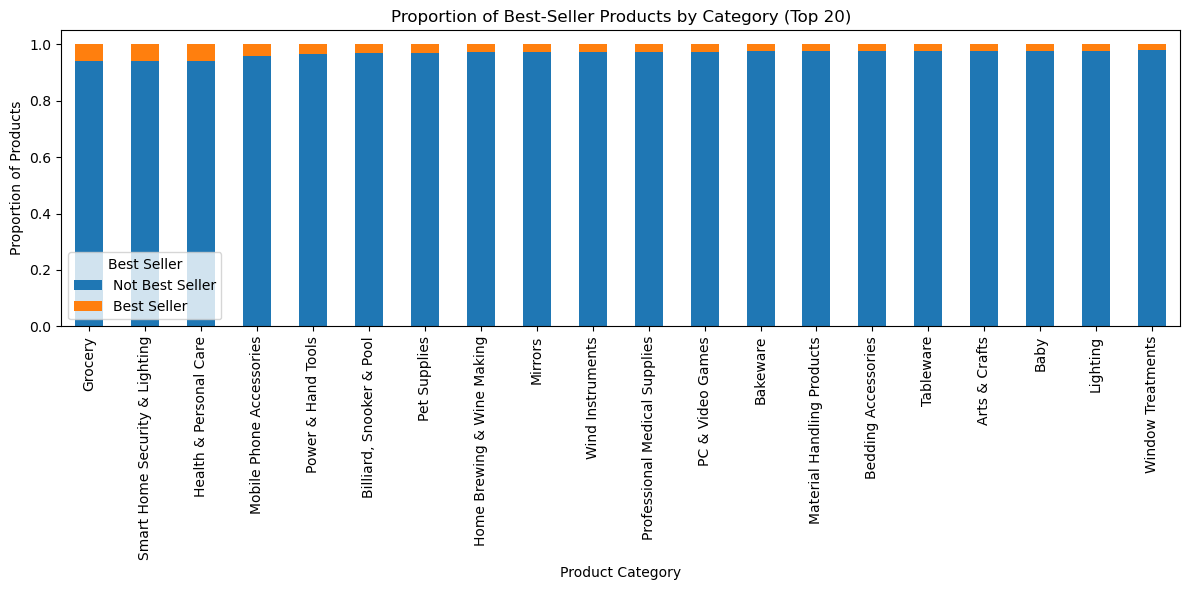

In [12]:
crosstab_norm_top.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Proportion of Best-Seller Products by Category (Top 20)")
plt.ylabel("Proportion of Products")
plt.xlabel("Product Category")
plt.legend(title="Best Seller", labels=["Not Best Seller", "Best Seller"])
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# PART 2

In [13]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

df_no_outliers = df[
    (df["price"] >= Q1 - 1.5 * IQR) &
    (df["price"] <= Q3 + 1.5 * IQR)
]


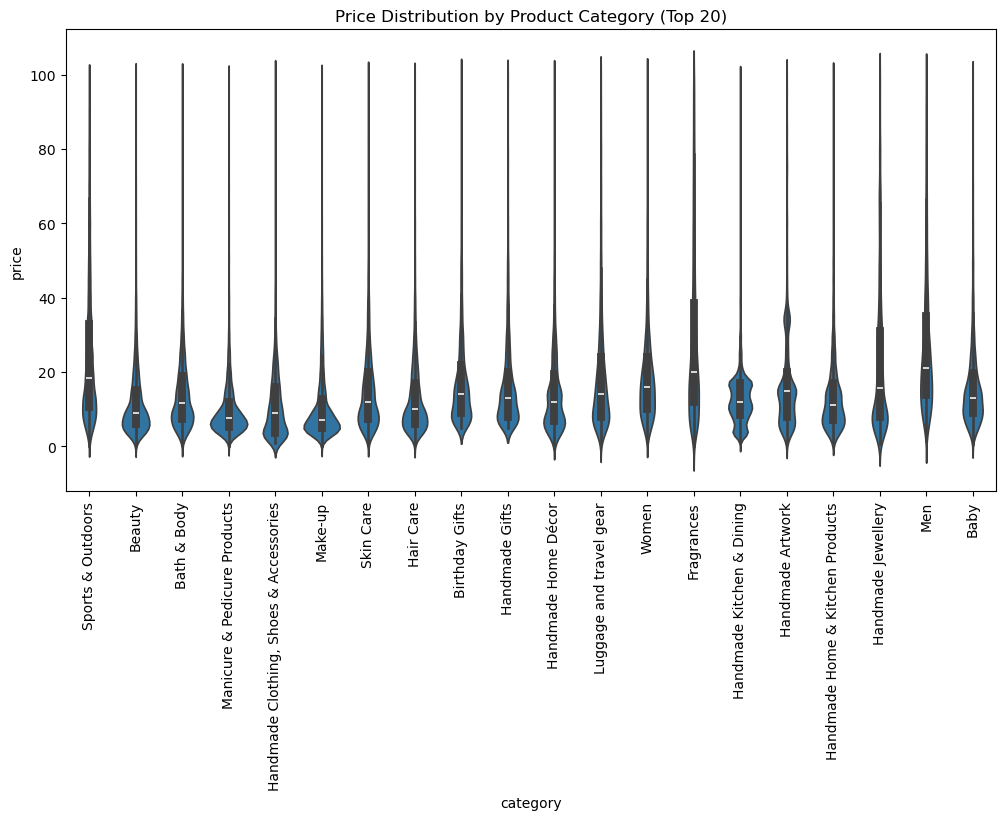

In [14]:
top20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

plt.figure(figsize=(12,6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top20_categories)],
    order=top20_categories,
    x="category",
    y="price"
)

plt.xticks(rotation=90)
plt.title("Price Distribution by Product Category (Top 20)")
plt.show()


In [15]:
df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)


category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

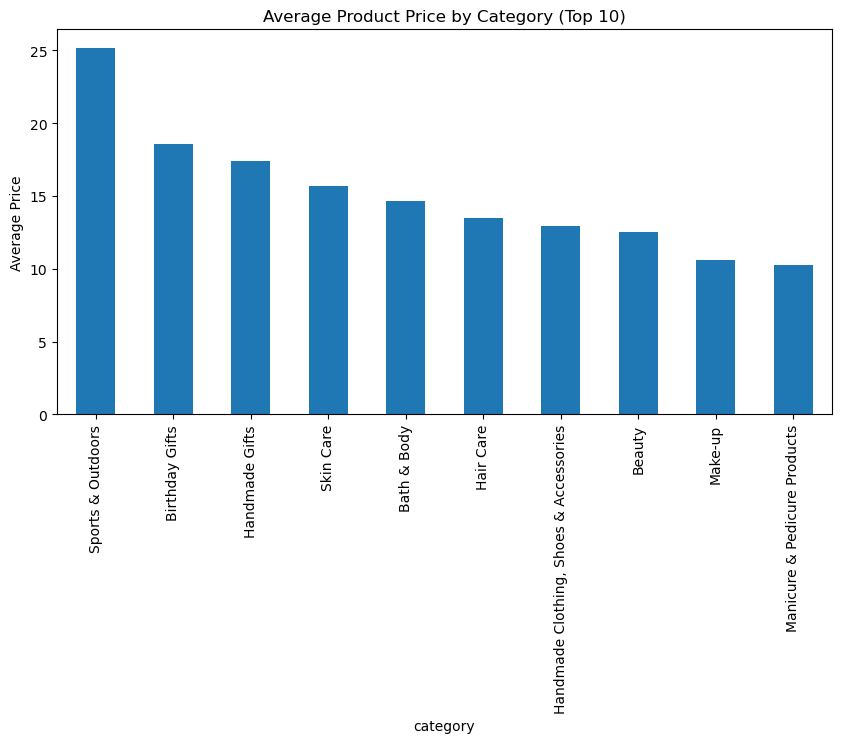

In [16]:
top10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price.plot(kind="bar", figsize=(10,5))
plt.title("Average Product Price by Category (Top 10)")
plt.ylabel("Average Price")
plt.show()


In [17]:
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)


category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

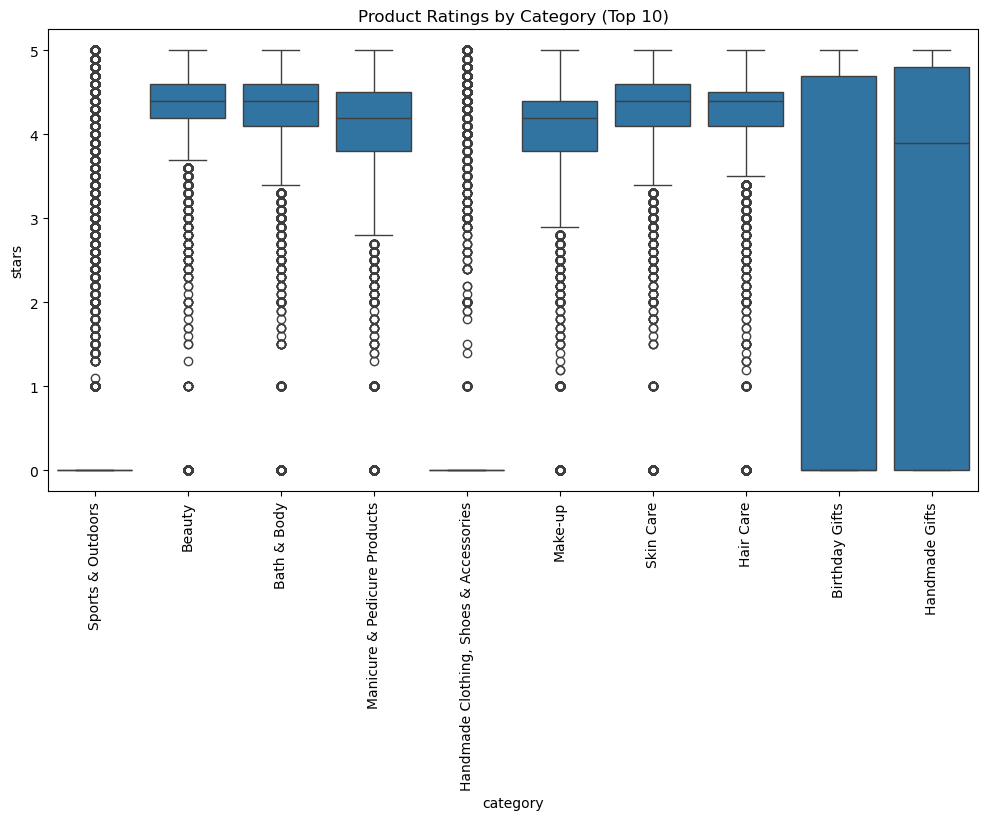

In [18]:
top10_rating_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top10_rating_categories)],
    order=top10_rating_categories,
    x="category",
    y="stars"
)

plt.xticks(rotation=90)
plt.title("Product Ratings by Category (Top 10)")
plt.show()


In [19]:
df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)


category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

#  PART 3

In [20]:
corr_price_stars = df_no_outliers["price"].corr(df_no_outliers["stars"])
corr_price_stars


np.float64(-0.07767299878181352)

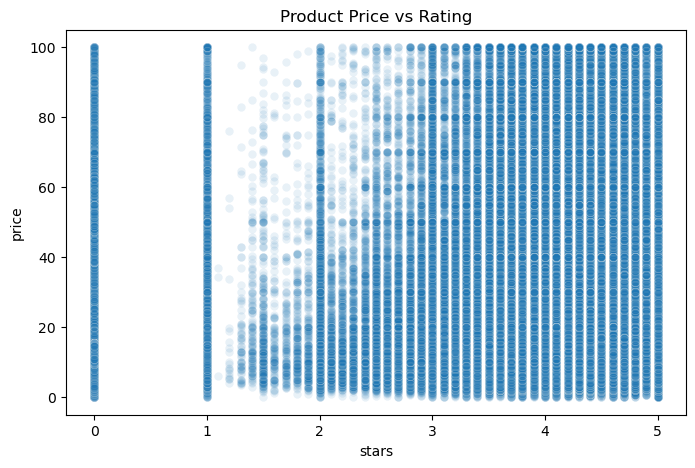

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df_no_outliers,
    x="stars",
    y="price",
    alpha=0.1
)

plt.title("Product Price vs Rating")
plt.show()


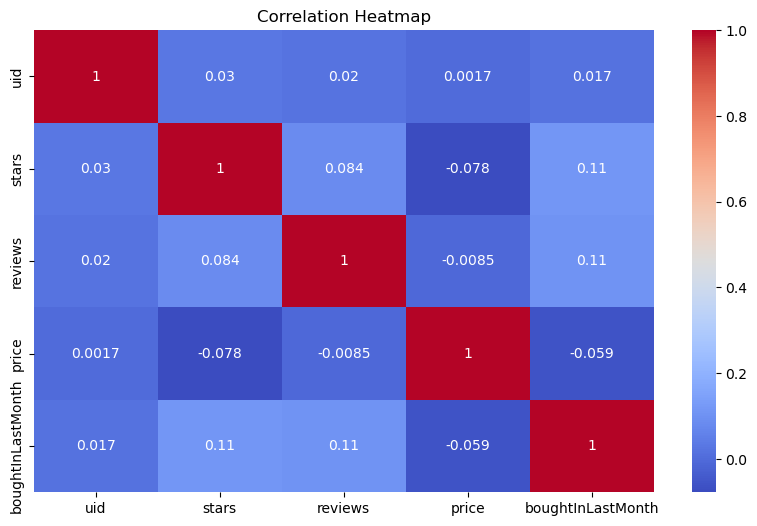

In [22]:
numeric_df = df_no_outliers.select_dtypes(include="number")

plt.figure(figsize=(10,6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()


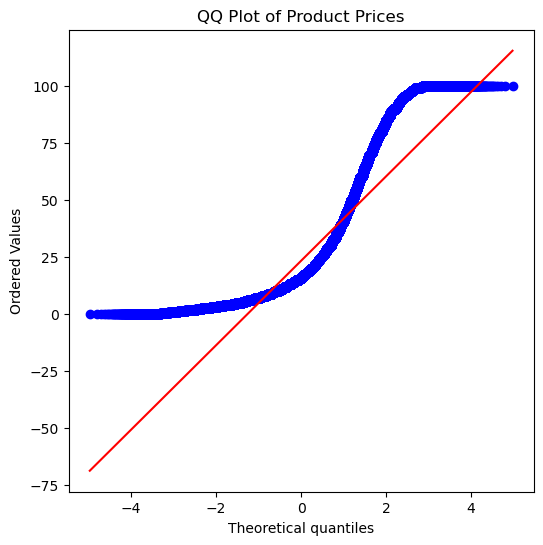

In [23]:
plt.figure(figsize=(6,6))
probplot(df_no_outliers["price"], plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()
